# Transfer learning - MobileNetV2 classification and YOLO bird/cat/dog detection

The original Windows-local dataset was unavailable. Per your instruction to find suitable data, classification uses a deterministic CIFAR-10 bird/cat/dog subset (60 train, 10 validation, 10 test images per class). Detection uses bird/cat/dog-labelled images from COCO128, with a disjoint image-level train/validation split. These tiny datasets are for runnable practical demonstrations, NOT reliable accuracy benchmarks.

The MobileNetV2 freeze, classifier training, fine-tuning and evaluation sequence and YOLO11n training/validation/prediction are preserved. Classification uses the required MobileNetV2 [-1,1] preprocessing instead of the original [0,1] scaling. Fine-tuning keeps BatchNorm layers frozen. All 5+5 classification epochs and 10 detection epochs are retained; detection image size is reduced from 640 to 320 for CPU execution.

Sources: https://keras.io/api/datasets/cifar10/ and https://docs.ultralytics.com/datasets/detect/coco128 . Independent student reference for SPPU BE IT task scope (not an official syllabus): https://github.com/RanjeetKumbhar01/SPPU-BE-IT-DL-ASSIGNMENTS .


## Cell 1: Check optional dependencies

For Google Colab, install only the tested Ultralytics package without downgrading its included NumPy, OpenCV, TensorFlow or PyTorch. The previous numpy<2/opencv<4.12 pins stalled on current Python 3.13. This replacement setup and the remaining revised cells passed a genuine hosted Colab CPU run on Python 3.13.18 / TensorFlow 2.21.0 / PyTorch 2.11.0 on 2 November 2026. The setup output below is from that hosted run; other saved outputs/plots remain the separately recorded Python 3.10 / TensorFlow 2.16.1 run. In a separate local environment use the recorded requirements rather than --no-deps alone. Internet is needed for downloads.

In [3]:
import sys, subprocess; print(sys.version, flush=True); subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--no-deps', 'ultralytics==8.3.40']); print('Dependencies available')

3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Dependencies available


## Cell 2: Set up reproducibility

Set seeds and CPU limits before loading TensorFlow. This notebook forces CPU so it does not require paid accelerators.

In [2]:
# Reproducible CPU-friendly setup. Colab already includes the main libraries.
import os, random
os.environ["TF_NUM_INTRAOP_THREADS"] = "2"
os.environ["TF_NUM_INTEROP_THREADS"] = "1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"
import numpy as np
import tensorflow as tf
random.seed(42)
np.random.seed(42)
tf.keras.utils.set_random_seed(42)
print("TensorFlow:", tf.__version__)
print("Execution device: CPU")


TensorFlow: 2.16.1
Execution device: CPU

## Cell 3: Prepare public classification data

Download CIFAR-10 from an archive mirror and verify the original SHA256 before Keras loads it. Select bird/cat/dog (original IDs 2/3/5). For each class keep 60 training, 10 validation and 10 official-test images. Save folder-based PNGs for the original directory-loader approach. These are tiny selected subsets, not full-dataset accuracy results.

In [3]:
from pathlib import Path
import shutil, zipfile
from PIL import Image
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt

# Official CIFAR-10 mirror, verified against original archive SHA256.
# Pre-cache the exact archive so Keras does not use its slow original host.
from tensorflow.keras.utils import get_file
get_file("cifar-10-batches-py-target_archive", origin="https://github.com/Digital-Media/cv_data/releases/download/cifar-10/cifar-10-python.tar.gz", file_hash="6d958be074577803d12ecdefd02955f39262c83c16fe9348329d7fe0b5c001ce")
# Keep original official test images for test only.
(x_train, y_train), (x_test, y_test) = cifar10.load_data()
BASE_PATH = Path.cwd() / "data" / "cifar_bird_cat_dog"
for label, name in [(2,"bird"),(3,"cat"),(5,"dog")]:
    train_ids = np.flatnonzero(y_train.ravel() == label)
    test_ids = np.flatnonzero(y_test.ravel() == label)
    for split, images in [("train",x_train[train_ids[:60]]), ("validation",x_train[train_ids[60:70]]), ("test",x_test[test_ids[:10]])]:
        folder = BASE_PATH / split / name
        folder.mkdir(parents=True, exist_ok=True)
        for i, image in enumerate(images):
            Image.fromarray(image).save(folder / f"{i:04d}.png")
print("Classification dataset: 180 train, 30 validation, 30 test; bird/cat/dog")
IMG_SIZE=(128,128)
BATCH_SIZE=16

Classification dataset: 180 train, 30 validation, 30 test; bird/cat/dog

## Cell 4: Load and preprocess images

Resize images to 128 x 128. Augment only training images; keep validation/test fixed. MobileNetV2 preprocess_input scales [0,255] to [-1,1], unlike the original generic rescale=1/255. Directory names assign bird=0, cat=1, dog=2; assert that all splits agree.

In [4]:
train_datagen = ImageDataGenerator(preprocessing_function=preprocess_input,
    rotation_range=20, width_shift_range=0.2, height_shift_range=0.2, horizontal_flip=True)
eval_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)
train_data = train_datagen.flow_from_directory(BASE_PATH/"train", target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode="categorical", seed=42)
validation_data = eval_datagen.flow_from_directory(BASE_PATH/"validation", target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode="categorical", shuffle=False)
test_data = eval_datagen.flow_from_directory(BASE_PATH/"test", target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode="categorical", shuffle=False)
assert train_data.class_indices == validation_data.class_indices == test_data.class_indices
print("Classes:",train_data.class_indices)

Found 180 images belonging to 3 classes.
Found 30 images belonging to 3 classes.
Found 30 images belonging to 3 classes.
Classes: {'bird': 0, 'cat': 1, 'dog': 2}

## Cell 5: Build the transfer-learning classifier

Load ImageNet-pretrained MobileNetV2 without its original classifier. Freeze its weights, average spatial feature maps, add Dense(128), Dropout(0.5), and a 3-class softmax. training=False keeps BatchNorm running statistics stable. Compile with Adam and categorical cross-entropy because directory loaders return one-hot labels.

In [5]:
base_model = MobileNetV2(weights="imagenet", include_top=False, input_shape=(128,128,3))
base_model.trainable = False
inputs = tf.keras.Input(shape=(128,128,3))
x = base_model(inputs, training=False)
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation="relu")(x)
x = Dropout(0.5)(x)
outputs = Dense(3, activation="softmax")(x)
model = Model(inputs, outputs)
model.compile(optimizer=Adam(0.001), loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## Cell 6: Train the new head

Train only the custom classifier for 5 epochs, then measure the test loss/accuracy before fine-tuning. The base convolutional features remain fixed.

In [6]:
history1 = model.fit(train_data, validation_data=validation_data, epochs=5, verbose=2)
test_loss1, test_accuracy1 = model.evaluate(test_data, verbose=0)
print("Before fine-tuning:",test_loss1,test_accuracy1)

Epoch 1/5
12/12 - 4s - 311ms/step - accuracy: 0.3778 - loss: 1.8816 - val_accuracy: 0.4000 - val_loss: 1.2424
Epoch 2/5
12/12 - 1s - 72ms/step - accuracy: 0.5056 - loss: 1.3269 - val_accuracy: 0.6000 - val_loss: 0.9209
Epoch 3/5
12/12 - 1s - 65ms/step - accuracy: 0.6222 - loss: 0.9309 - val_accuracy: 0.5667 - val_loss: 1.0359
Epoch 4/5
12/12 - 1s - 67ms/step - accuracy: 0.4944 - loss: 1.0061 - val_accuracy: 0.5333 - val_loss: 0.9484
Epoch 5/5
12/12 - 1s - 66ms/step - accuracy: 0.6944 - loss: 0.7696 - val_accuracy: 0.5000 - val_loss: 0.9525
Before fine-tuning: 0.9967086911201477 0.4333333373069763

## Cell 7: Fine-tune upper layers

Unfreeze the base model, then freeze every layer except the last 20 and keep BatchNorm layers frozen. Recompile after changing trainability, use a smaller learning rate 0.0001, and train 5 more epochs. A lower learning rate reduces damage to pretrained features.

In [7]:
base_model.trainable = True
for layer in base_model.layers[:-20]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False
model.compile(optimizer=Adam(0.0001), loss="categorical_crossentropy", metrics=["accuracy"])
history2 = model.fit(train_data, validation_data=validation_data, epochs=5, verbose=2)
test_loss2, test_accuracy2 = model.evaluate(test_data, verbose=0)
print("After fine-tuning:",test_loss2,test_accuracy2)

Epoch 1/5
12/12 - 4s - 353ms/step - accuracy: 0.5833 - loss: 0.8971 - val_accuracy: 0.5333 - val_loss: 0.9292
Epoch 2/5
12/12 - 1s - 79ms/step - accuracy: 0.5778 - loss: 0.8977 - val_accuracy: 0.5000 - val_loss: 0.9585
Epoch 3/5
12/12 - 1s - 75ms/step - accuracy: 0.6111 - loss: 0.7870 - val_accuracy: 0.5000 - val_loss: 0.9779
Epoch 4/5
12/12 - 1s - 111ms/step - accuracy: 0.6333 - loss: 0.7726 - val_accuracy: 0.7000 - val_loss: 0.8318
Epoch 5/5
12/12 - 1s - 79ms/step - accuracy: 0.7111 - loss: 0.7116 - val_accuracy: 0.3667 - val_loss: 1.0728
After fine-tuning: 0.9574477076530457 0.46666666865348816

## Cell 8: Plot both training stages

Combine the two histories for accuracy and loss plots. The vertical line separates frozen-head training from fine-tuning. Tiny validation and test sets make these curves/accuracies unstable.

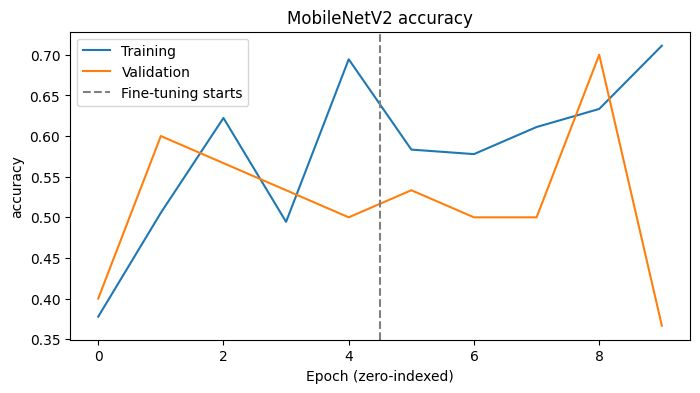

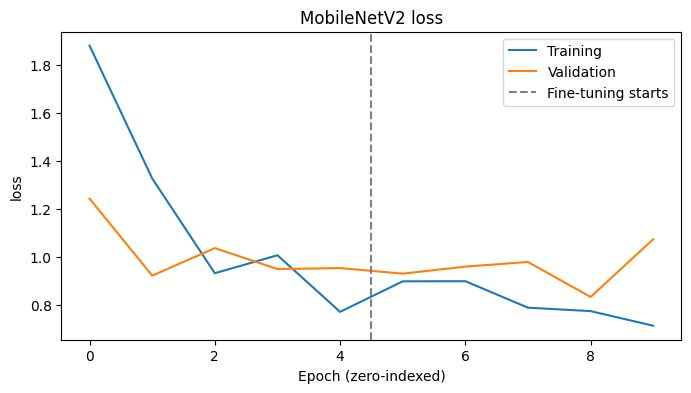

In [8]:
for metric in ["accuracy","loss"]:
    plt.figure(figsize=(8,4))
    plt.plot(history1.history[metric]+history2.history[metric],label="Training")
    plt.plot(history1.history["val_"+metric]+history2.history["val_"+metric],label="Validation")
    plt.axvline(4.5,linestyle="--",color="gray",label="Fine-tuning starts")
    plt.xlabel("Epoch (zero-indexed)"); plt.ylabel(metric)
    plt.title("MobileNetV2 "+metric); plt.legend(); plt.show()

## Cell 9: Prepare real detection annotations

Download public COCO128, verify archive paths before extraction, and retain images with bird/cat/dog bounding boxes. Remap COCO IDs 14/15/16 to 0/1/2. Deterministically hold every fourth image out: 11 train and 4 validation images, with no shared images. YAML records relative image folders and class names. Box coordinates stay in YOLO format: class, x_center, y_center, width, height, normalized to [0,1]. No independent detection test set is available; class coverage is very uneven.

In [9]:
# Download COCO128 and filter real bounding-box labels to bird/cat/dog.
from tensorflow.keras.utils import get_file
import yaml
archive = get_file("coco128.zip", origin="https://github.com/ultralytics/assets/releases/download/v0.0.0/coco128.zip")
raw_root = Path.cwd()/"data"/"raw_coco"
with zipfile.ZipFile(archive) as z:
    # Only extract expected dataset members; refuse path traversal.
    for member in z.infolist():
        dest=(raw_root/member.filename).resolve()
        if not dest.is_relative_to(raw_root.resolve()):
            raise ValueError("Unsafe archive member")
    z.extractall(raw_root)
source=raw_root/"coco128"
dest=Path.cwd()/"data"/"coco_bird_cat_dog"
class_map={14:0,15:1,16:2}
records=[]
for label in sorted((source/"labels"/"train2017").glob("*.txt")):
    lines=[]
    for row in label.read_text().splitlines():
        fields=row.split()
        if int(fields[0]) in class_map:
            fields[0]=str(class_map[int(fields[0])]); lines.append(" ".join(fields))
    if lines:
        records.append((label.stem,lines))
# Deterministic split: every fourth image is validation; no image is in both.
for i,(stem,lines) in enumerate(records):
    split="val" if i%4==0 else "train"
    (dest/"images"/split).mkdir(parents=True,exist_ok=True)
    (dest/"labels"/split).mkdir(parents=True,exist_ok=True)
    shutil.copy(source/"images"/"train2017"/(stem+".jpg"),dest/"images"/split/(stem+".jpg"))
    (dest/"labels"/split/(stem+".txt")).write_text("\n".join(lines)+"\n")
config={"path":str(dest.resolve()),"train":"images/train","val":"images/val","names":{0:"bird",1:"cat",2:"dog"}}
data_yaml=dest/"data.yaml"
data_yaml.write_text(yaml.safe_dump(config))
for split in ["train","val"]:
    print(split,"images:",len(list((dest/"images"/split).glob("*.jpg"))))
print("Small pipeline demonstration only; validation is not a robust benchmark.")

train images: 11
val images: 4
Small pipeline demonstration only; validation is not a robust benchmark.

## Cell 10: Fine-tune YOLO11n

Load pretrained YOLO11n and fine-tune it for 10 epochs on the annotated subset. The 320-pixel image size and batch 4 are CPU-friendly changes from the original 640/batch 8. YOLO predicts boxes and class scores, unlike MobileNet classification. The dataset is only a pipeline demonstration.

In [10]:
from ultralytics import YOLO
import cv2
# Explicit CPU and zero workers keep this runnable without a paid GPU.
detector=YOLO("yolo11n.pt")
results=detector.train(data=str(data_yaml),epochs=10,imgsz=320,batch=4,
    device="cpu",workers=0,name="bird_cat_dog_detection",project="runs",
    exist_ok=True,seed=42,verbose=False,plots=False)

New https://pypi.org/project/ultralytics/8.4.198 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.40 🚀 Python-3.10.12 torch-2.5.1+cpu CPU (Intel Xeon Processor)
engine/trainer: task=detect, mode=train, model=yolo11n.pt, data=/downloads/practical-prep/data/coco_bird_cat_dog/data.yaml, epochs=10, time=None, patience=100, batch=4, imgsz=320, save=True, save_period=-1, cache=False, device=cpu, workers=0, project=runs, name=bird_cat_dog_detection, exist_ok=True, pretrained=True, optimizer=auto, verbose=False, seed=42, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=False, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_ma

Overriding model.yaml nc=80 with nc=3

                   from  n    params  module                                       arguments                     
  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 
  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                
  2                  -1  1      6640  ultralytics.nn.modules.block.C3k2            [32, 64, 1, False, 0.25]      
  3                  -1  1     36992  ultralytics.nn.modules.conv.Conv             [64, 64, 3, 2]                
  4                  -1  1     26080  ultralytics.nn.modules.block.C3k2            [64, 128, 1, False, 0.25]     
  5                  -1  1    147712  ultralytics.nn.modules.conv.Conv             [128, 128, 3, 2]              
  6                  -1  1     87040  ultralytics.nn.modules.block.C3k2            [128, 128, 1, True]           
  7                  -1  1    295424  ultralytics

YOLO11n summary: 319 layers, 2,590,425 parameters, 2,590,409 gradients, 6.4 GFLOPs

Transferred 448/499 items from pretrained weights
TensorBoard: Start with 'tensorboard --logdir runs/bird_cat_dog_detection', view at http://localhost:6006/
Freezing layer 'model.23.dfl.conv.weight'

train: Scanning /downloads/practical-prep/data/coco_bird_cat_dog/labels/train...:   0%|          | 0/11 [00:00<?, ?it/s]train: Scanning /downloads/practical-prep/data/coco_bird_cat_dog/labels/train... 11 images, 0 backgrounds, 0 corrupt: 100%|██████████| 11/11 [00:00<00:00, 2824.79it/s]

train: New cache created: /downloads/practical-prep/data/coco_bird_cat_dog/labels/train.cache

val: New cache created: /downloads/practical-prep/data/coco_bird_cat_dog/labels/val.cache
optimizer: 'optimizer=auto' found, ignoring 'lr0=0.01' and 'momentum=0.937' and determining best 'optimizer', 'lr0' and 'momentum' automatically... 

... (29 outputs left out)

                   all          4          4     0.0101          1      0.532      0.409


10 epochs completed in 0.005 hours.
Optimizer stripped from runs/bird_cat_dog_detection/weights/last.pt, 5.4MB
Optimizer stripped from runs/bird_cat_dog_detection/weights/best.pt, 5.4MB

Validating runs/bird_cat_dog_detection/weights/best.pt...
Ultralytics 8.3.40 🚀 Python-3.10.12 torch-2.5.1+cpu CPU (Intel Xeon Processor)
YOLO11n summary (fused): 238 layers, 2,582,737 parameters, 0 gradients, 6.3 GFLOPs

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95):   0%|          | 0/1 [00:00<?, ?it/s]                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 1/1 [00:00<00:00,  8.50it/s]                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 1/1 [00:00<00:00,  8.45it/s]

                   all          4          4    0.00988          1       0.81      0.642
Speed: 0.4ms preprocess, 25.2ms inference, 0.0ms loss, 1.5ms postprocess per image

## Cell 11: Validate and show detection output

Validate on the four held-out images and print precision, recall, mAP@0.5 and mAP@0.5:0.95. Metrics on this tiny set are not reliable generalization claims; validation is also used to pick training checkpoints. Run prediction on one validation image at confidence 0.25. The fresh run produced 0 retained boxes on this image: the plot honestly shows that, rather than claiming successful detection. Low-confidence/no boxes is a model outcome, not a Python execution error.

Ultralytics 8.3.40 🚀 Python-3.10.12 torch-2.5.1+cpu CPU (Intel Xeon Processor)
YOLO11n summary (fused): 238 layers, 2,582,737 parameters, 0 gradients, 6.3 GFLOPs

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95):   0%|          | 0/1 [00:00<?, ?it/s]                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 1/1 [00:00<00:00,  8.76it/s]                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 1/1 [00:00<00:00,  8.69it/s]

                   all          4          4    0.00988          1       0.81      0.642
Speed: 0.4ms preprocess, 24.3ms inference, 0.0ms loss, 1.6ms postprocess per image
Validation metrics: {'metrics/precision(B)': 0.009879755709227443, 'metrics/recall(B)': 1.0, 'metrics/mAP50(B)': 0.8103571428571428, 'metrics/mAP50-95(B)': 0.6417152852916315, 'fitness': 0.6585794710481827}
Demo image: 000000000042.jpg (a validation image, not an independent test)

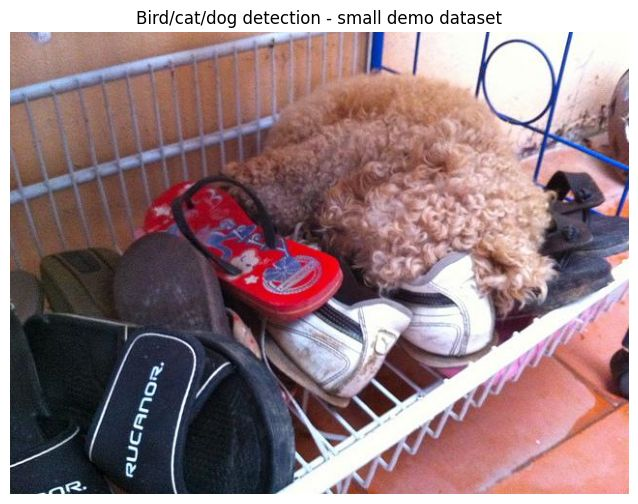

Detected boxes: 0

In [11]:
metrics=detector.val(data=str(data_yaml),device="cpu",workers=0,plots=False)
print("Validation metrics:",metrics.results_dict)
image_path=str(sorted((dest/"images"/"val").glob("*.jpg"))[0])
print("Demo image:",Path(image_path).name,"(a validation image, not an independent test)")
predictions=detector.predict(source=image_path,conf=0.25,device="cpu",verbose=False)
for result in predictions:
    plt.figure(figsize=(8,6))
    plt.imshow(cv2.cvtColor(result.plot(),cv2.COLOR_BGR2RGB))
    plt.axis("off");plt.title("Bird/cat/dog detection - small demo dataset");plt.show()
    print("Detected boxes:",len(result.boxes))